# Predicting How Receivers Move: Combine Drills Against a Season of NFL Tracking

Code for the Big Data Bowl 2027 writeup. It goes from the competition CSVs to every number and figure the writeup quotes.

All analysis lives in the `bdb27` Python package ([repository](https://github.com/alexanderschatzberg/nfl-big-data-bowl-2027)); the cells below only call it and show the results.

**Running it**

- **Locally:** from the repository root, `uv sync`, put the competition CSVs in `data/`, then run this notebook (`uv run python -m ipykernel install --sys-prefix --name bdb27` once, then `uv run jupyter nbconvert --to notebook --execute --ExecutePreprocessor.kernel_name=bdb27 --ExecutePreprocessor.timeout=3600 report/notebook.ipynb --output notebook.ipynb`). A full run from raw CSVs takes about 10 minutes on an 8-core laptop; reruns reuse the Parquet files.
- **On Kaggle:** attach the competition data, turn Internet on, and run. The first cell installs the package from GitHub, reads CSVs from the read-only input directory and writes everything else to `/kaggle/working`.

Two environment variables control paths: `BDB27_RAW` (the CSVs, may be read-only) and `BDB27_DATA` (Parquet and cached artifacts, must be writable).

In [1]:
import os, subprocess, sys, time
from pathlib import Path

ON_KAGGLE = Path("/kaggle/input").exists()
REPO = "git+https://github.com/alexanderschatzberg/nfl-big-data-bowl-2027@main"

if ON_KAGGLE:
    # The package: a copy attached as a Kaggle dataset wins; otherwise install from GitHub (needs Internet on).
    attached = sorted(Path("/kaggle/input").glob("*/src/bdb27"))
    if attached:
        sys.path.insert(0, str(attached[0].parent))
    else:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", REPO], check=True)
    raw = sorted(Path("/kaggle/input").rglob("combine_tracking.csv"))[0].parent
    os.environ.setdefault("BDB27_RAW", str(raw))
    os.environ.setdefault("BDB27_DATA", "/kaggle/working/bdb27")
    FIG_DIR = Path("/kaggle/working/figures")
else:
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
    os.environ.setdefault("BDB27_DATA", str(root / "data"))
    os.environ.setdefault("BDB27_RAW", str(root / "data"))
    FIG_DIR = Path(os.environ.get("BDB27_FIGURES", root / "report" / "figures"))

os.environ["PYTHONWARNINGS"] = "ignore"  # also reaches the parallel workers
import warnings
warnings.filterwarnings("ignore")  # constant-input warnings from permuted correlations
import pandas as pd
from IPython.display import Image, display

pd.set_option("display.width", 220, "display.max_columns", 30, "display.precision", 3)
START = time.time()
print("CSVs:", os.environ["BDB27_RAW"], "| artifacts:", os.environ["BDB27_DATA"], "| figures:", FIG_DIR)

CSVs: /Users/alexander/Desktop/developer/nfl-big-data-bowl-2027/data | artifacts: /Users/alexander/Desktop/developer/nfl-big-data-bowl-2027/data | figures: /Users/alexander/Desktop/developer/nfl-big-data-bowl-2027/report/figures


## 1. Prepare the data

Converts the CSVs to Parquet (skipped if already done), then builds:

- per-attempt movement features from the 10 Hz **Combine tracking**, z-scored within drill × position × draft class. Clips shorter than 65% of the typical length for their drill and class are dropped first (29 of 6,307), because they end before the drill does;
- the same features on every regular-season **game tracking** play, from the snap;
- context-adjusted player outcomes (separation over expected and so on), cross-fitted by player.

The clip tensors for the neural models are skipped (`neural=False`); see the appendix.

In [2]:
from bdb27 import cli, conventional, development, figures, interactions, leaders, matched, report, usage, value

t0 = time.time()
cli.prep(neural=False)
print(f"prep: {time.time() - t0:.0f} s")

prep: 97 s


## 2. The stopwatch check

Every standard Combine number against regular-season outcomes, by position, with outcomes centred within on-field alignment. `p_family` is a min-p permutation test over all of a position's tests. Shown: wide receivers, main effects.

In [3]:
stopwatch = report.stopwatch(n_perm=1000)
wr = stopwatch[(stopwatch.position == "WR") & (stopwatch.kind == "main")]
show = wr[wr.a.isin(["forty", "combine_weight", "combine_height", "log_pick"]) & wr.outcome.isin(report.STOPWATCH_OUTCOMES)]
show.pivot(index="a", columns="outcome", values="effect").round(2)

outcome,game_speed_p99,sep_oe_all,targets_per_route,yards_per_route
a,,,,
combine_height,-0.25,-0.41,-0.08,-0.05
combine_weight,-0.40,-0.51,0.06,0.02
forty,-0.55,-0.18,-0.12,-0.13
log_pick,-0.20,0.16,-0.41,-0.40


In [4]:
wr.sort_values("p").head(8)[["a", "outcome", "n", "effect", "p", "p_family"]]

,a,outcome,n,effect,p,p_family
0,log_pick,snaps_per_season,107,-0.698,6.968e-17,9.990e-04
1,ngs_college_production_score,snaps_per_season,107,0.455,8.437e-07,1.998e-03
2,forty,game_speed_p99,65,-0.546,2.580e-06,1.998e-03
3,vertical,snaps_per_season,96,0.438,7.882e-06,2.997e-03
4,combine_weight,sep_oe_all,69,-0.505,9.434e-06,3.996e-03
5,combine_weight,separation_raw,69,-0.488,2.139e-05,9.990e-03
6,combine_height,separation_raw,69,-0.463,6.159e-05,1.798e-02
8,log_pick,targets_per_route,69,-0.408,5.004e-04,1.289e-01


## 3. Matched transfer: the same trait in the drill and in the game

Each row pairs a drill family with the game situation it rehearses and measures one movement feature identically on both sides. The game side is the player's 90th-percentile play. `partial_rho` removes 40 time, weight, height and alignment; `partial_q` is the false-discovery rate across all rows.

In [5]:
transfer = matched.table()
transfer.sort_values("partial_p")

,position,trait,n,rho,p,partial_rho,partial_p,by_class,partial_q
1,WR,40 tracked top speed,58,0.550,7.754e-06,0.438,5.941e-04,"{2023: 0.38, 2024: 0.68, 2025: 0.6}",0.017
2,WR,stop-route braking,54,0.424,1.408e-03,0.428,1.233e-03,"{2023: 0.45, 2024: 0.45, 2025: 0.43}",0.018
21,DB,40 tracked top speed,67,0.364,2.474e-03,0.231,6.021e-02,"{2023: 0.37, 2024: 0.39, 2025: 0.38}",0.443
17,OL,pull top speed,75,0.207,7.542e-02,0.217,6.104e-02,"{2023: 0.26, 2024: 0.11, 2025: 0.16}",0.443
10,DL,hoop lateral acceleration,78,0.390,4.173e-04,0.199,8.085e-02,"{2023: 0.27, 2024: 0.64, 2025: 0.34}",0.447
12,DL,agility braking,82,0.544,1.293e-07,0.180,1.049e-01,"{2023: 0.57, 2024: 0.54, 2025: 0.45}",0.447
19,DB,break-drill burst,78,-0.133,2.467e-01,-0.179,1.176e-01,"{2023: -0.22, 2024: -0.22, 2025: 0.08}",0.447
6,WR,cut turn rate,70,0.219,6.849e-02,0.176,1.448e-01,"{2023: -0.11, 2024: 0.25, 2025: 0.53}",0.447
11,DL,hoop curve speed,78,0.357,1.348e-03,0.166,1.467e-01,"{2023: 0.27, 2024: 0.44, 2025: 0.35}",0.447
13,OL,pass-set burst,74,0.358,1.762e-03,0.162,1.676e-01,"{2023: 0.26, 2024: 0.44, 2025: 0.23}",0.447


### Who the result is about

The five hardest and five softest brakers in the drills, with where each ranks for braking on hitch routes in games. Rank 1 brakes hardest. The second line counts how many of each group are in the top half of the game ranking.

In [6]:
named = leaders.top_bottom()
print(named.attrs)
named

{'n': 54, 'top_in_game_top_half': 5, 'bottom_in_game_top_half': 2}


,Receiver,Draft,Drill braking rank,Hardest stops on game hitch routes (yd/s²),Game braking rank (of 54)
0,Arian Smith,"2025, pick 110",1,7.3,16
1,Rome Odunze,"2024, pick 9",2,7.2,24
2,Troy Franklin,"2024, pick 102",3,7.6,7
3,Tyler Scott,"2023, pick 133",4,8.1,1
4,Adonai Mitchell,"2024, pick 52",5,7.6,6
5,Quentin Johnston,"2023, pick 21",50,7.2,27
6,Jalen McMillan,"2024, pick 92",51,7.3,18
7,Luke McCaffrey,"2024, pick 100",52,6.9,42
8,Ryan Flournoy,"2024, pick 216",53,6.6,47
9,Brian Thomas,"2024, pick 23",54,7.2,30


### Robustness, placebos and the season benchmark

The headline pair under every variation I tried, with placebos that should be null. Then the yardstick: the drills and the same game measure from a player's previous season, both predicting the same NFL season. (Season pairs need at least 12 qualifying plays in each season; some players contribute two pairs, so intervals resample players.) `combine_given_season` is what the drills add once a season is known. Last, whether drill braking is the 3-cone or shuttle in disguise.

In [7]:
robust = matched.robustness(n_boot=2000)
print("bootstrap 95% interval:", robust.attrs["ci95"], "| permutation p:", round(float(robust.attrs["perm_p"]), 4))
robust

bootstrap 95% interval: [0.178, 0.632] | permutation p: 0.0045


,variant,n,rho,p,partial_rho,partial_p,by_class
0,as specified,54,0.424,1.408e-03,0.428,1.233e-03,"{2023: 0.45, 2024: 0.45, 2025: 0.43}"
1,game quantile 0.5,54,0.215,1.179e-01,0.183,1.861e-01,"{2023: 0.1, 2024: 0.27, 2025: 0.26}"
2,game quantile 0.75,54,0.338,1.252e-02,0.291,3.271e-02,"{2023: 0.2, 2024: 0.46, 2025: 0.32}"
3,game quantile 0.85,54,0.387,3.841e-03,0.376,5.105e-03,"{2023: 0.29, 2024: 0.52, 2025: 0.49}"
4,game quantile 0.95,54,0.250,6.791e-02,0.261,5.626e-02,"{2023: 0.31, 2024: 0.2, 2025: 0.27}"
5,min plays 10,63,0.390,1.567e-03,0.392,1.467e-03,"{2023: 0.45, 2024: 0.46, 2025: 0.18}"
6,min plays 30,49,0.419,2.697e-03,0.430,2.045e-03,"{2023: 0.31, 2024: 0.49, 2025: 0.64}"
7,min plays 40,41,0.386,1.280e-02,0.345,2.703e-02,"{2023: 0.33, 2024: 0.49}"
8,feature dec_win10,54,0.319,1.872e-02,0.334,1.357e-02,"{2023: 0.19, 2024: 0.38, 2025: 0.48}"
9,feature dec_p95,54,0.387,3.811e-03,0.368,6.160e-03,"{2023: 0.23, 2024: 0.42, 2025: 0.47}"


In [8]:
benchmarks = {name: matched.benchmark(name) for name in (report.HEADLINE, report.SPEED)}
keep = ["season_pairs", "season_players", "combine_to_next_season", "combine_next_ci", "season_to_next_season", "season_ci",
        "difference_ci", "variance_share", "combine_given_season", "combine_given_season_p", "n", "combine_to_game",
        "drill_to_drill"]
display(pd.DataFrame({k: {c: b[c] for c in keep} for k, b in benchmarks.items()}).T)
agility = matched.agility_check(report.HEADLINE)
agility

,season_pairs,season_players,combine_to_next_season,combine_next_ci,season_to_next_season,season_ci,difference_ci,variance_share,combine_given_season,combine_given_season_p,n,combine_to_game,drill_to_drill
stop-route braking,47,33,0.333,"[-0.01650114533163512, 0.610179366055023]",0.56,"[0.21043432092256933, 0.7432700283894838]","[-0.24134849570555622, 0.6202539494708263]",0.354,0.1,0.581,54,0.424,0.257
40 tracked top speed,48,34,0.466,"[0.13922783106420844, 0.6920063236033512]",0.672,"[0.4246517193044263, 0.8171085261752937]","[-0.002616338474982347, 0.44649192465328774]",0.48,0.144,0.416,58,0.55,NaN


,time,n,rho,p
0,three_cone,32,-0.031,0.866
1,short_shuttle,36,-0.082,0.634
2,forty,94,-0.007,0.950


## 4. Does braking buy anything?

`value.table()` is a **pre-specified** test: its definition (the module docstring, printed below) was committed to the repository before it was run. The `primary` row is the confirmatory test; the rest are secondary.

In [9]:
print(value.__doc__)
value.table()

Does Combine braking pay off against man coverage? A pre-specified test.

Stop-drill braking transfers to hitch routes (`matched.py`) but showed no link
to separation when all hitches were pooled. Against zone the defender sits on
the route however the receiver stops, so the pooled test may have hidden a
man-coverage effect. This was written, and committed, before it was run:

PRIMARY (one test, two-sided, alpha 0.05)
  Players    WRs with stop-drill braking and >= 8 qualifying plays.
  Predictor  mean class-relative z of `dec_win05` over the comeback and curl drills.
  Plays      regular season, not nullified, HITCH route, MAN_COVERAGE, separation recorded.
  Outcome    player mean of separation at pass forward, after removing the linear
             effect of cushion at play level.
  Statistic  Spearman partial correlation net of 40 time, weight, height and
             modal alignment (`matched.test`). Expected sign: positive.

SECONDARY (reported, not confirmatory)
  The same again

,predictor,outcome,coverage,primary,n,rho,p,partial_rho,partial_p,by_class
0,combine braking,separation,MAN_COVERAGE,True,41,0.073,0.651,0.104,0.519,"{2023: 0.56, 2024: -0.4}"
1,combine braking,separation,ZONE_COVERAGE,False,61,-0.112,0.389,-0.173,0.183,"{2023: -0.07, 2024: -0.25, 2025: -0.09}"
2,combine braking,target,MAN_COVERAGE,False,28,0.150,0.445,0.046,0.816,"{2023: 0.11, 2024: 0.13}"
3,combine braking,yac,any,False,41,-0.094,0.559,-0.018,0.913,"{2023: -0.01, 2024: -0.09}"
4,game hitch braking,separation,MAN_COVERAGE,False,41,0.156,0.331,0.231,0.146,"{2023: 0.46, 2024: -0.2}"
5,game hitch braking,separation,ZONE_COVERAGE,False,54,-0.120,0.388,-0.189,0.172,"{2023: -0.21, 2024: -0.2, 2025: 0.26}"
6,game hitch braking,target,MAN_COVERAGE,False,28,0.390,0.040,-0.113,0.568,"{2023: 0.32, 2024: 0.62}"
7,game hitch braking,yac,any,False,41,-0.352,0.024,-0.285,0.071,"{2023: -0.28, 2024: -0.31}"


In [10]:
chain = report.chain(n_boot=2000)
chain

,stage,label,n,partial_rho,p,lo,hi,pre_specified
0,Combine movement and the same movement in games,"Braking in the comeback and curl drills, and o...",54,0.428,1.233e-03,0.178,0.632,False
1,Combine movement and the same movement in games,"Top speed in the 40-yard dash, and on go routes",58,0.438,5.941e-04,0.128,0.631,False
2,Combine braking and results on hitch routes,Stop-drill braking: separation against man cov...,41,0.104,5.190e-01,-0.266,0.490,True
3,Combine braking and results on hitch routes,Stop-drill braking: separation against zone co...,61,-0.173,1.834e-01,-0.437,0.137,False
4,Combine braking and results on hitch routes,Stop-drill braking: target rate against man co...,28,0.046,8.163e-01,-0.397,0.535,False
5,Combine braking and results on hitch routes,"Stop-drill braking: yards after the catch, com...",41,-0.018,9.131e-01,-0.400,0.345,False
6,Game braking and results on hitch routes,Game hitch braking: separation against man cov...,41,0.231,1.462e-01,-0.161,0.544,False
7,Game braking and results on hitch routes,Game hitch braking: separation against zone co...,54,-0.189,1.716e-01,-0.482,0.116,False
8,Game braking and results on hitch routes,Game hitch braking: target rate against man co...,28,-0.113,5.678e-01,-0.530,0.346,False
9,Game braking and results on hitch routes,"Game hitch braking: yards after the catch, com...",41,-0.285,7.088e-02,-0.648,0.055,False


A null result from the Combine side could mean the drill measurement is poor. To check, I measured the movement **in games** instead, for eight features and four route sets, against separation and yards per route. Separation itself is a reliable player attribute (split-half reliability printed below).

In [11]:
game_movement = value.game_movement()
print("separation reliability:", round(game_movement.attrs["separation_reliability"], 2),
      "| tests with q < 0.10:", int((game_movement.q < 0.10).sum()), "of", len(game_movement))
game_movement.head(6)

separation reliability: 0.69 | tests with q < 0.10: 2 of 64


,routes,game_feature,outcome,n,partial_rho,p,q
44,go,brk_reacc_10,separation,17,0.740,6.799e-04,0.044
50,all,dec_win05,separation,77,-0.336,2.810e-03,0.090
47,go,path_eff,yards per route,56,-0.337,1.103e-02,0.235
63,all,path_eff,yards per route,70,-0.287,1.587e-02,0.254
32,go,vmax,separation,63,-0.270,3.247e-02,0.410
55,all,lat_acc,yards per route,70,0.238,4.715e-02,0.410


Braking and top speed are the two Combine traits that carry over to games. This cell checks how related they are to each other, and whether either one relates to separation against particular coverages (adjusted for route and cushion, net of weight, height and alignment). It also reports how closely a receiver's separation against man tracks his separation against zone.


In [12]:
coverage = value.coverage_profile()
print({k: round(v, 2) for k, v in coverage.attrs.items()})
coverage.pivot(index="coverage", columns="trait", values="partial_rho").round(2)


{'traits_rho': -0.13, 'traits_n': 91, 'man_zone_rho': 0.41, 'man_zone_n': 63}


trait,braking,top speed
coverage,,
Cover 1,0.06,-0.08
Cover 2,-0.08,-0.04
Cover 3,-0.09,0.15
Cover 4 or 6,0.10,-0.12
Man (all),-0.02,-0.08
Zone (all),-0.13,0.01


## 5. The wider search (mostly null)

Everything else that was tested, so the reader can see the denominator: usage, an all-pairs interaction scan, and season-over-season development.

In [13]:
use = usage.table()
use.sort_values("partial_p").head(6)

,position,trait,share,n,mean_share,rho,p,partial_rho,partial_p,by_class,partial_q
3,WR,cut turn rate,align_SLOT_WR,63,0.342,-0.185,1.460e-01,-0.236,0.063,"{2023: -0.32, 2024: -0.17, 2025: -0.11}",0.735
5,TE,route braking,route_HITCH,21,0.170,0.384,8.533e-02,0.383,0.086,{2023: 0.31},0.735
16,DB,40 tracked top speed,align_CB,60,0.416,0.202,1.222e-01,0.163,0.214,"{2023: 0.31, 2024: 0.48, 2025: -0.24}",0.876
2,WR,go-route drill top speed,route_GO,56,0.200,0.133,3.287e-01,-0.161,0.237,"{2023: 0.1, 2024: 0.25, 2025: 0.02}",0.876
10,DL,pass-rush drill burst,align_EDGE,76,0.500,0.470,1.799e-05,0.098,0.401,"{2023: 0.57, 2024: 0.34, 2025: 0.44}",0.876
15,DB,break-drill braking,align_HIGH_SAFETY,71,0.308,-0.036,7.648e-01,-0.097,0.422,"{2023: -0.1, 2024: -0.09, 2025: 0.14}",0.876


In [14]:
scan = report.interaction_scan(n_perm=1000)
print(len(scan), "interaction tests;", int((scan.p_family < 0.05).sum()), "with family-wise p < 0.05")
scan.sort_values("p_family").head(5)[["position", "tier", "a", "b", "outcome", "n", "beta", "p", "p_family", "by_class"]]

4589 interaction tests; 2 with family-wise p < 0.05


,position,tier,a,b,outcome,n,beta,p,p_family,by_class
1662,OL,stopwatch x stopwatch,ngs_college_production_score,log_pick,snaps_per_season,121,0.342,1.447e-05,0.015,"{2023: 0.29, 2024: 0.5, 2025: 0.31}"
1617,TE,stopwatch x drill,ngs_athleticism_score,route__lat_acc,snaps_per_season,42,0.451,1.159e-03,0.048,"{2023: 0.41, 2024: 0.13, 2025: 0.87}"
0,WR,drill x drill,stop__brk_reacc_10,cut__cut_turn_rate,game_speed_p99,66,0.475,3.745e-06,0.063,"{2023: 0.29, 2024: 0.18, 2025: 0.63}"
1,WR,drill x drill,stop__brk_time_under,cut__cut_turn_rate,game_speed_p99,66,-0.509,2.373e-05,0.186,"{2023: -0.17, 2024: -0.16, 2025: -0.77}"
2943,DL,stopwatch x drill,is_INTERIOR_LINE,agility__cod_reacc,game_speed_p99,85,-0.418,4.000e-04,0.293,"{2023: -0.3, 2024: -0.25, 2025: -0.56}"


In [15]:
seasons = development.seasons()
group = development.group_change(seasons)
group[group.p < 0.10]

,position,horizon,measure,n,season1,later,change_sd,improved,p,stability
4,WR,1->2,game_speed,39,0.134,0.004,-0.370,0.359,0.012,0.635
6,OL,1->2,pressure_kept_out,31,0.004,0.015,0.457,0.613,0.048,0.306
12,DL,1->2,game_speed,38,0.281,0.153,-0.327,0.289,0.043,0.616
18,WR,1->3,log_snaps,39,3.956,3.154,-0.334,0.282,0.045,0.621
23,DL,1->3,pressure_rate,15,0.006,0.019,0.489,0.733,0.073,0.668
26,DL,1->3,game_speed,17,0.398,0.152,-0.527,0.353,0.051,0.426
27,DB,1->3,log_snaps,35,3.866,3.161,-0.282,0.286,0.096,0.609


In [16]:
predict = development.predict_change(seasons, n_perm=1000)
retention = development.retention(seasons)
display(predict.head(5))
retention

,position,horizon,measure,predictor,n,partial_rho,p,rho_with_change,rho_with_season1,p_family
32,DL,1->3,log_snaps,rush__acc_win05,37,0.495,0.002,0.493,-0.049,0.136
32,OL,1->2,log_snaps,log_pick,83,-0.328,0.002,0.114,-0.825,0.159
3,OL,1->2,pressure_kept_out,broad_jump,27,0.540,0.004,0.464,-0.279,0.222
30,WR,1->3,targets_per_route,ngs_college_production_score,18,0.647,0.004,0.490,-0.289,0.386
39,DL,1->3,game_speed,broad_jump,15,0.689,0.004,0.069,0.453,0.294


,year,n,share_played,z_played,z_did_not,p_played,rho_snaps_among_played
0,1,118,0.797,0.056,-0.218,0.314,-0.118
1,2,74,0.757,0.171,-0.531,0.007,-0.074
2,3,37,0.730,0.238,-0.643,0.013,-0.024


## 6. Numbers quoted in the writeup, and the test count

In [17]:
tables = {"conventional": stopwatch, "matched": transfer, "interactions": scan, "usage": use, "development": predict}
numbers = report.numbers(tables, robust, benchmarks, chain, group, retention, game_movement, coverage, agility)
report.save(numbers, FIG_DIR.parent / "numbers.json")
print("tests run in this notebook:", numbers["tests"])
{k: numbers[k] for k in (report.HEADLINE, report.SPEED, "benchmark")}

tests run in this notebook: {'conventional': 518, 'matched': 29, 'interactions': 4589, 'usage': 17, 'development': 538, 'robustness': 18, 'value': 8, 'game_movement': 64, 'coverage_profile': 12, 'development_group': 29, 'agility': 3, 'total': 5825}


{'stop-route braking': {'n': 54,
  'rho': np.float64(0.42),
  'partial_rho': np.float64(0.43),
  'partial_p': 0.0012,
  'partial_q': np.float64(0.018),
  'by_class': {2023: np.float64(0.45),
   2024: np.float64(0.45),
   2025: np.float64(0.43)},
  'ci95': [0.178, 0.632],
  'perm_p': 0.0045},
 '40 tracked top speed': {'n': 58,
  'rho': np.float64(0.55),
  'partial_rho': np.float64(0.44),
  'partial_p': 0.00059,
  'partial_q': np.float64(0.017),
  'by_class': {2023: np.float64(0.38),
   2024: np.float64(0.68),
   2025: np.float64(0.6)}},
 'benchmark': {'stop-route braking': {'combine_to_game': 0.42,
   'combine_ci': [0.18, 0.62],
   'n': 54,
   'combine_to_next_season': 0.33,
   'combine_next_ci': [-0.02, 0.61],
   'season_to_next_season': 0.56,
   'season_ci': [0.21, 0.74],
   'difference_ci': [-0.24, 0.62],
   'variance_share': 0.35,
   'combine_given_season': 0.1,
   'combine_given_season_p': 0.58,
   'combine_given_season_n': 33,
   'season_pairs': 47,
   'season_players': 33,
   'ga

## 7. Figures

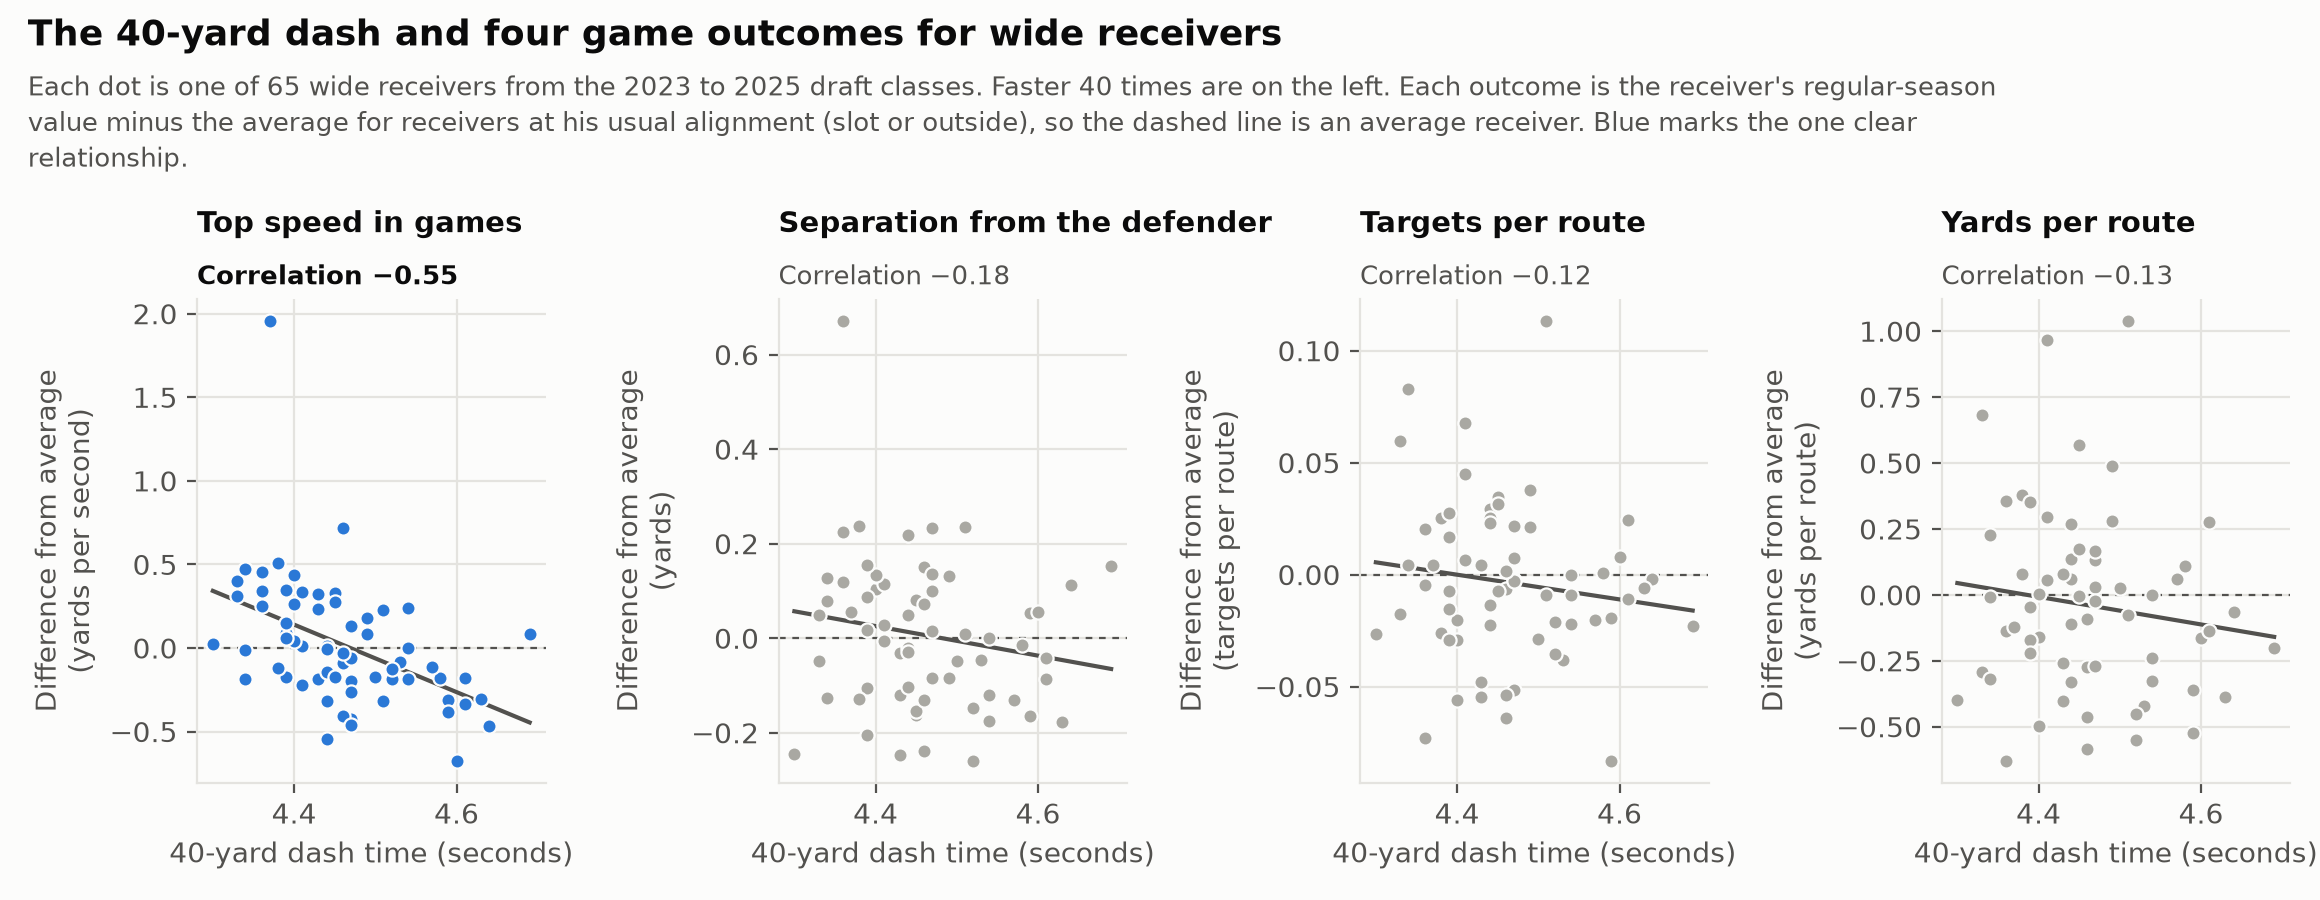

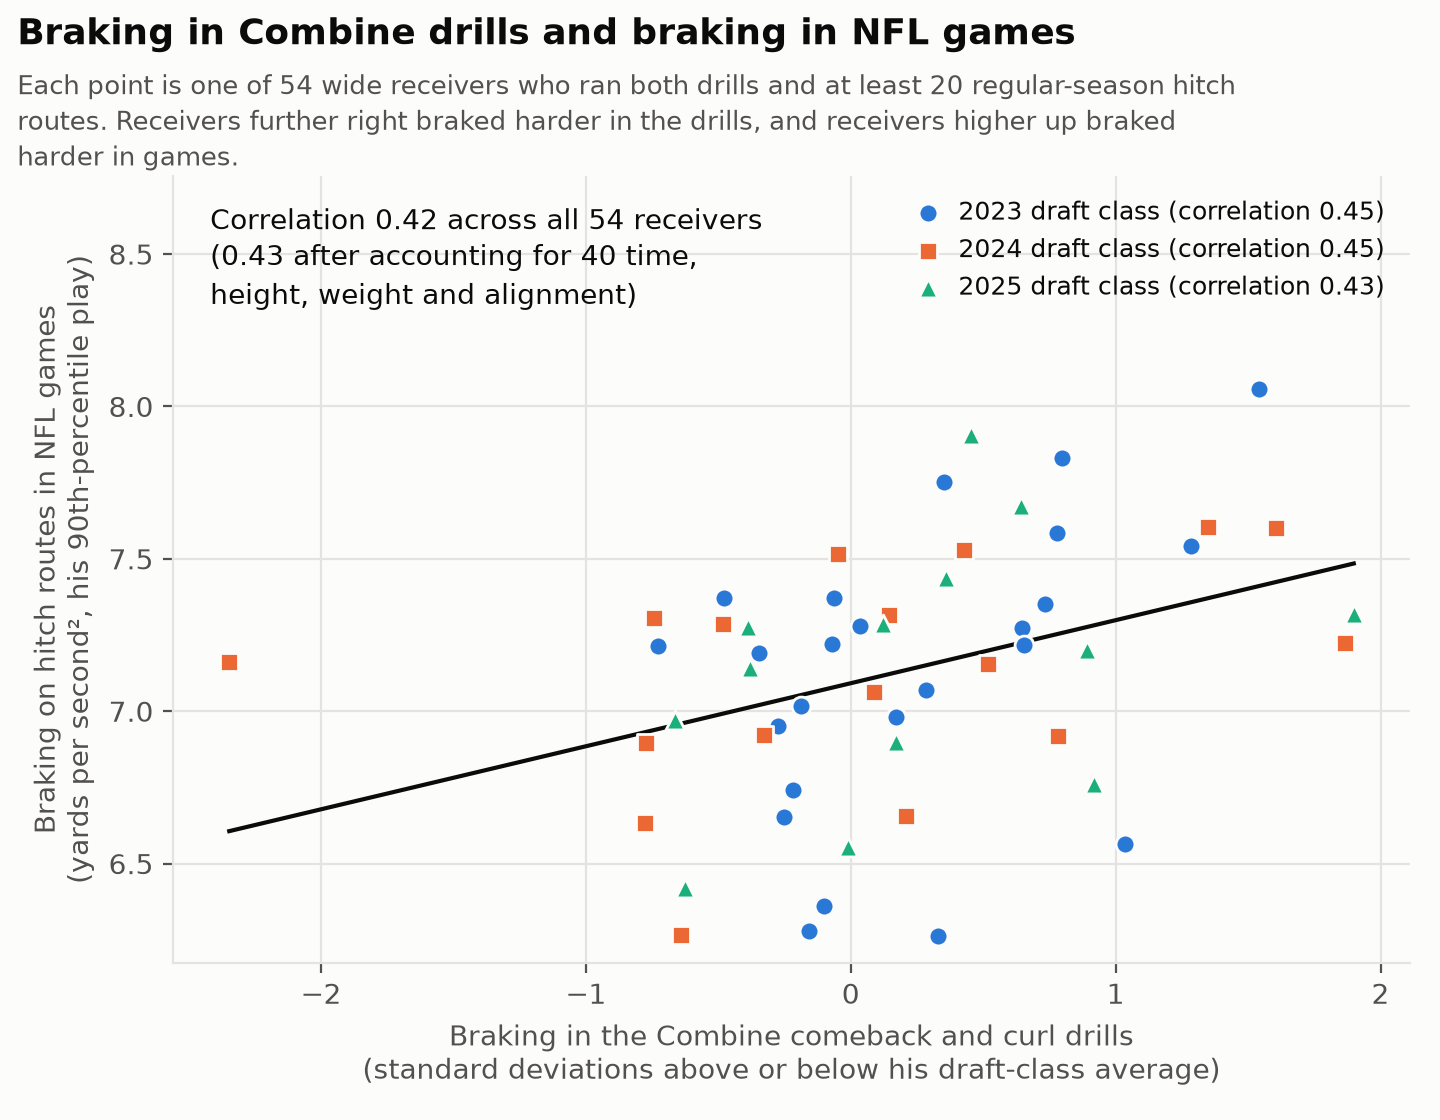

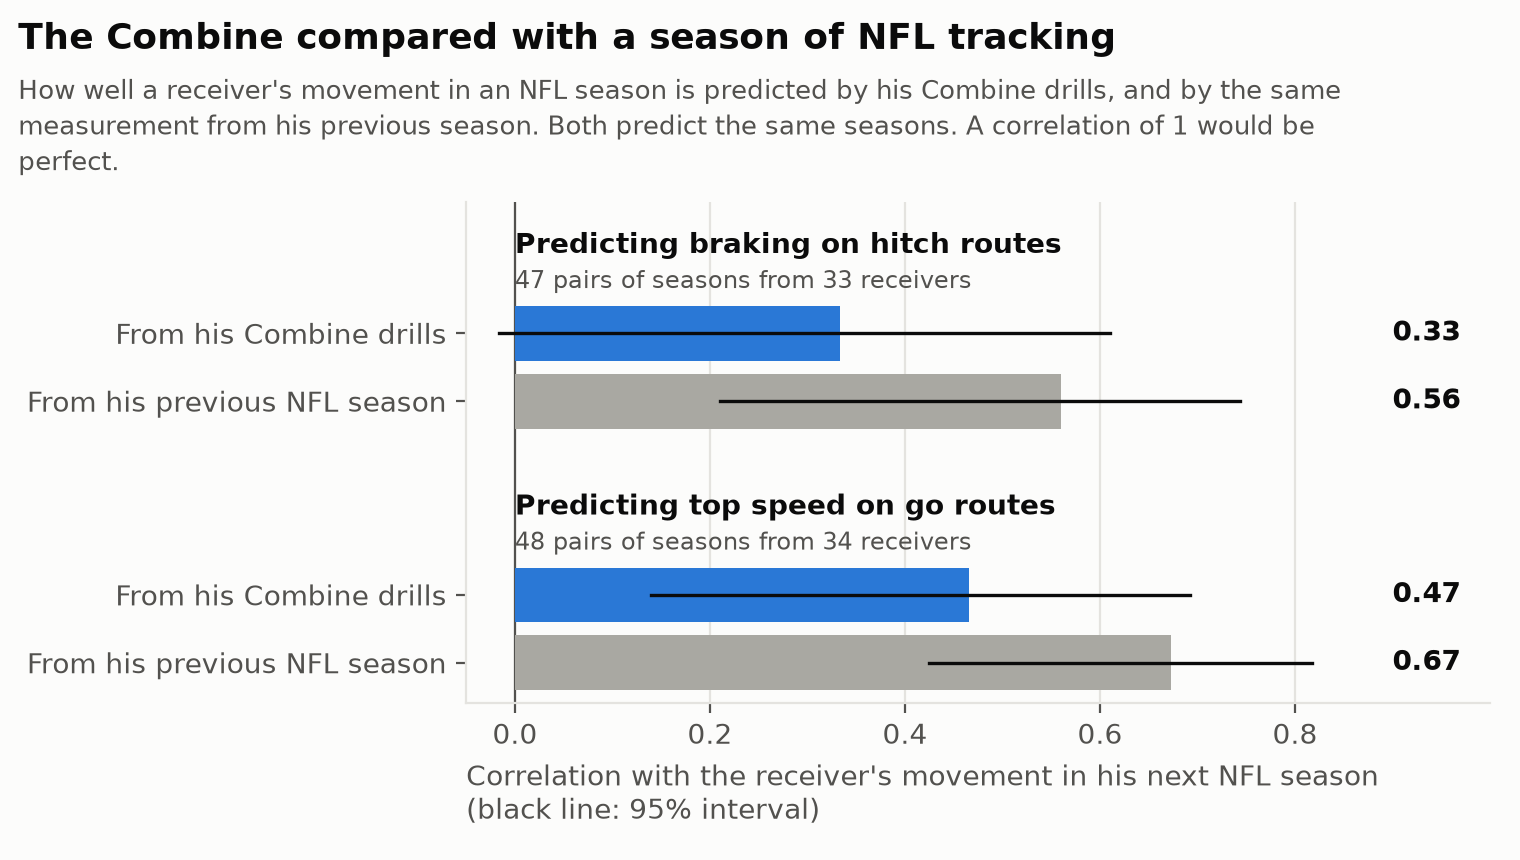

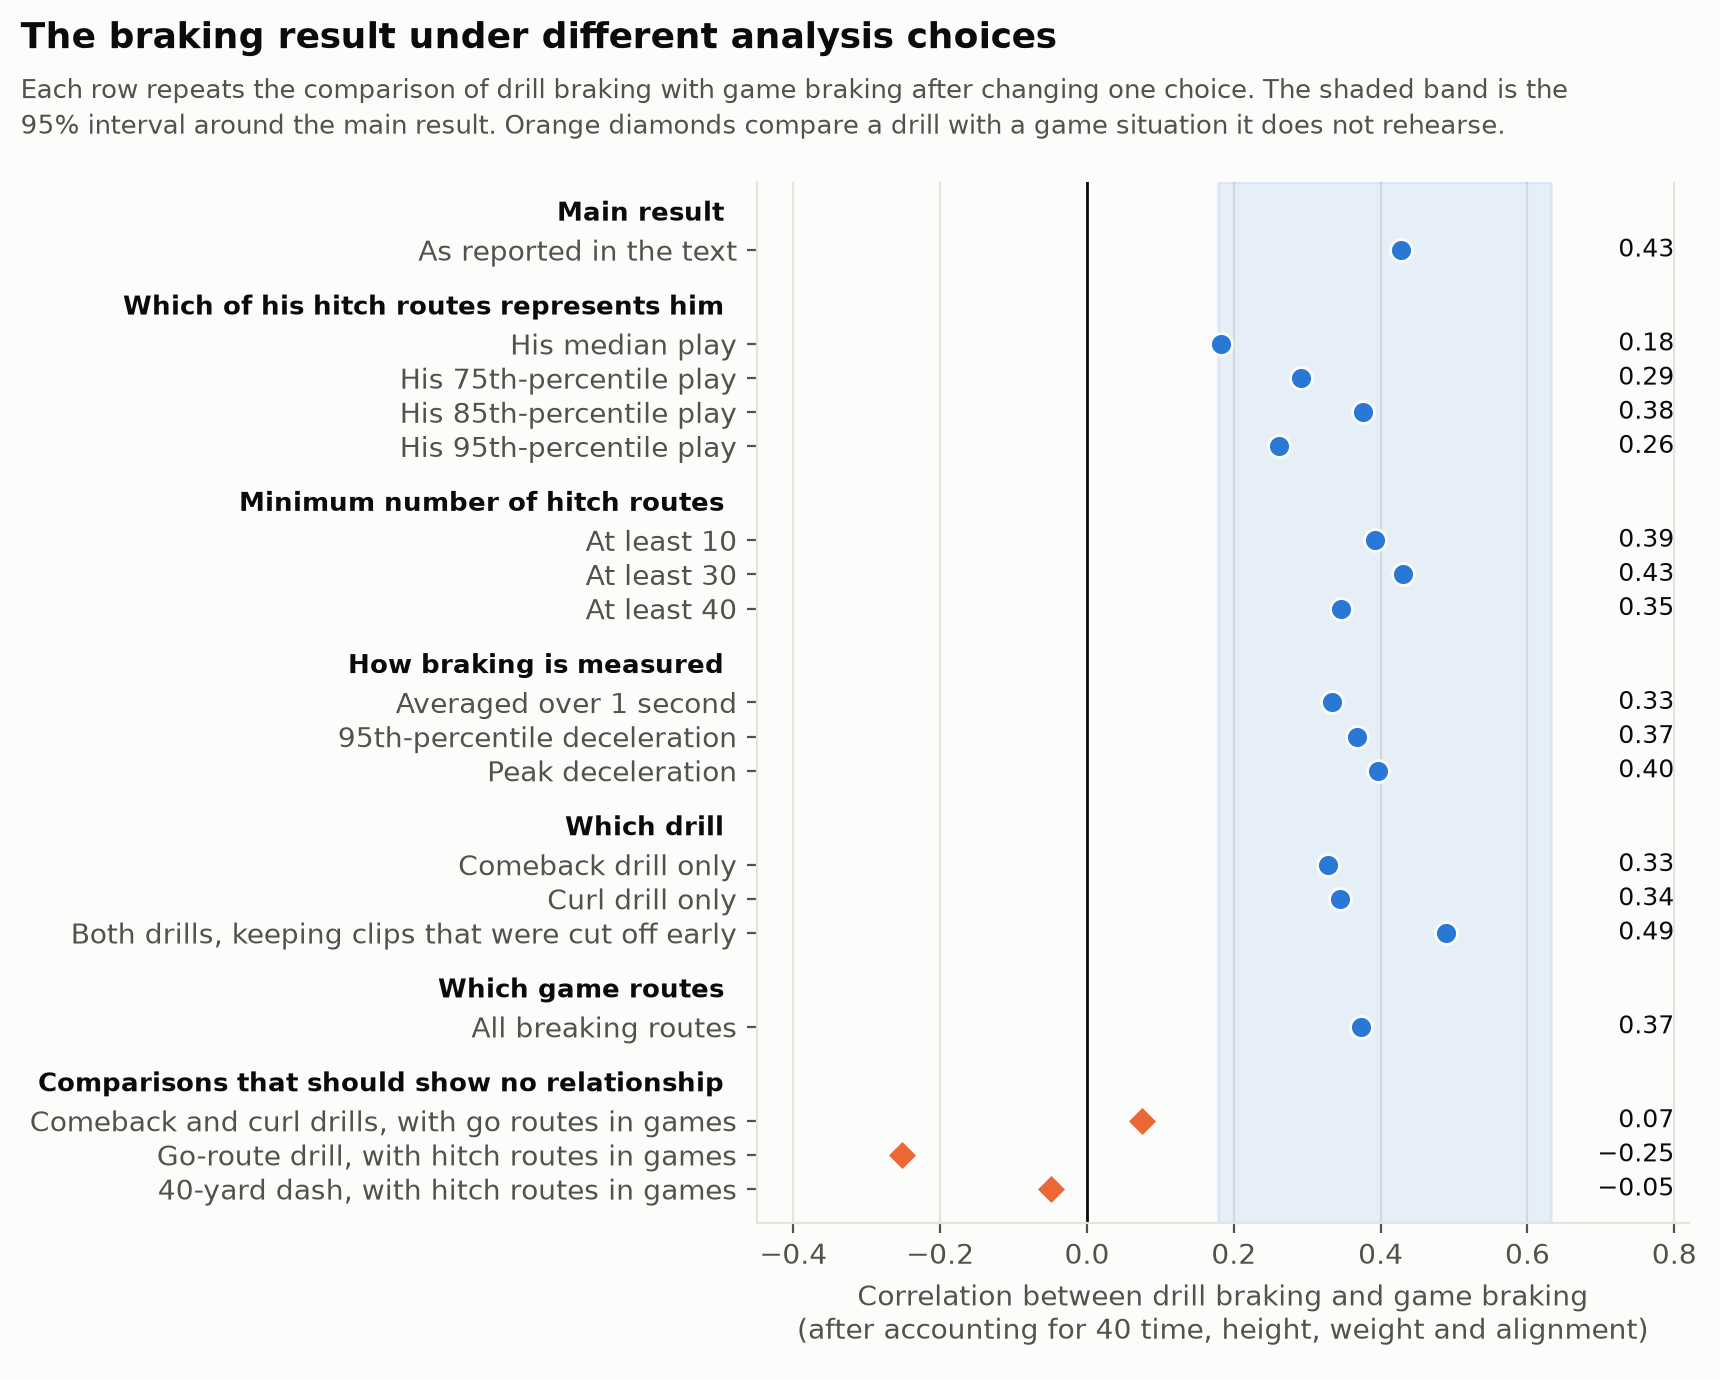

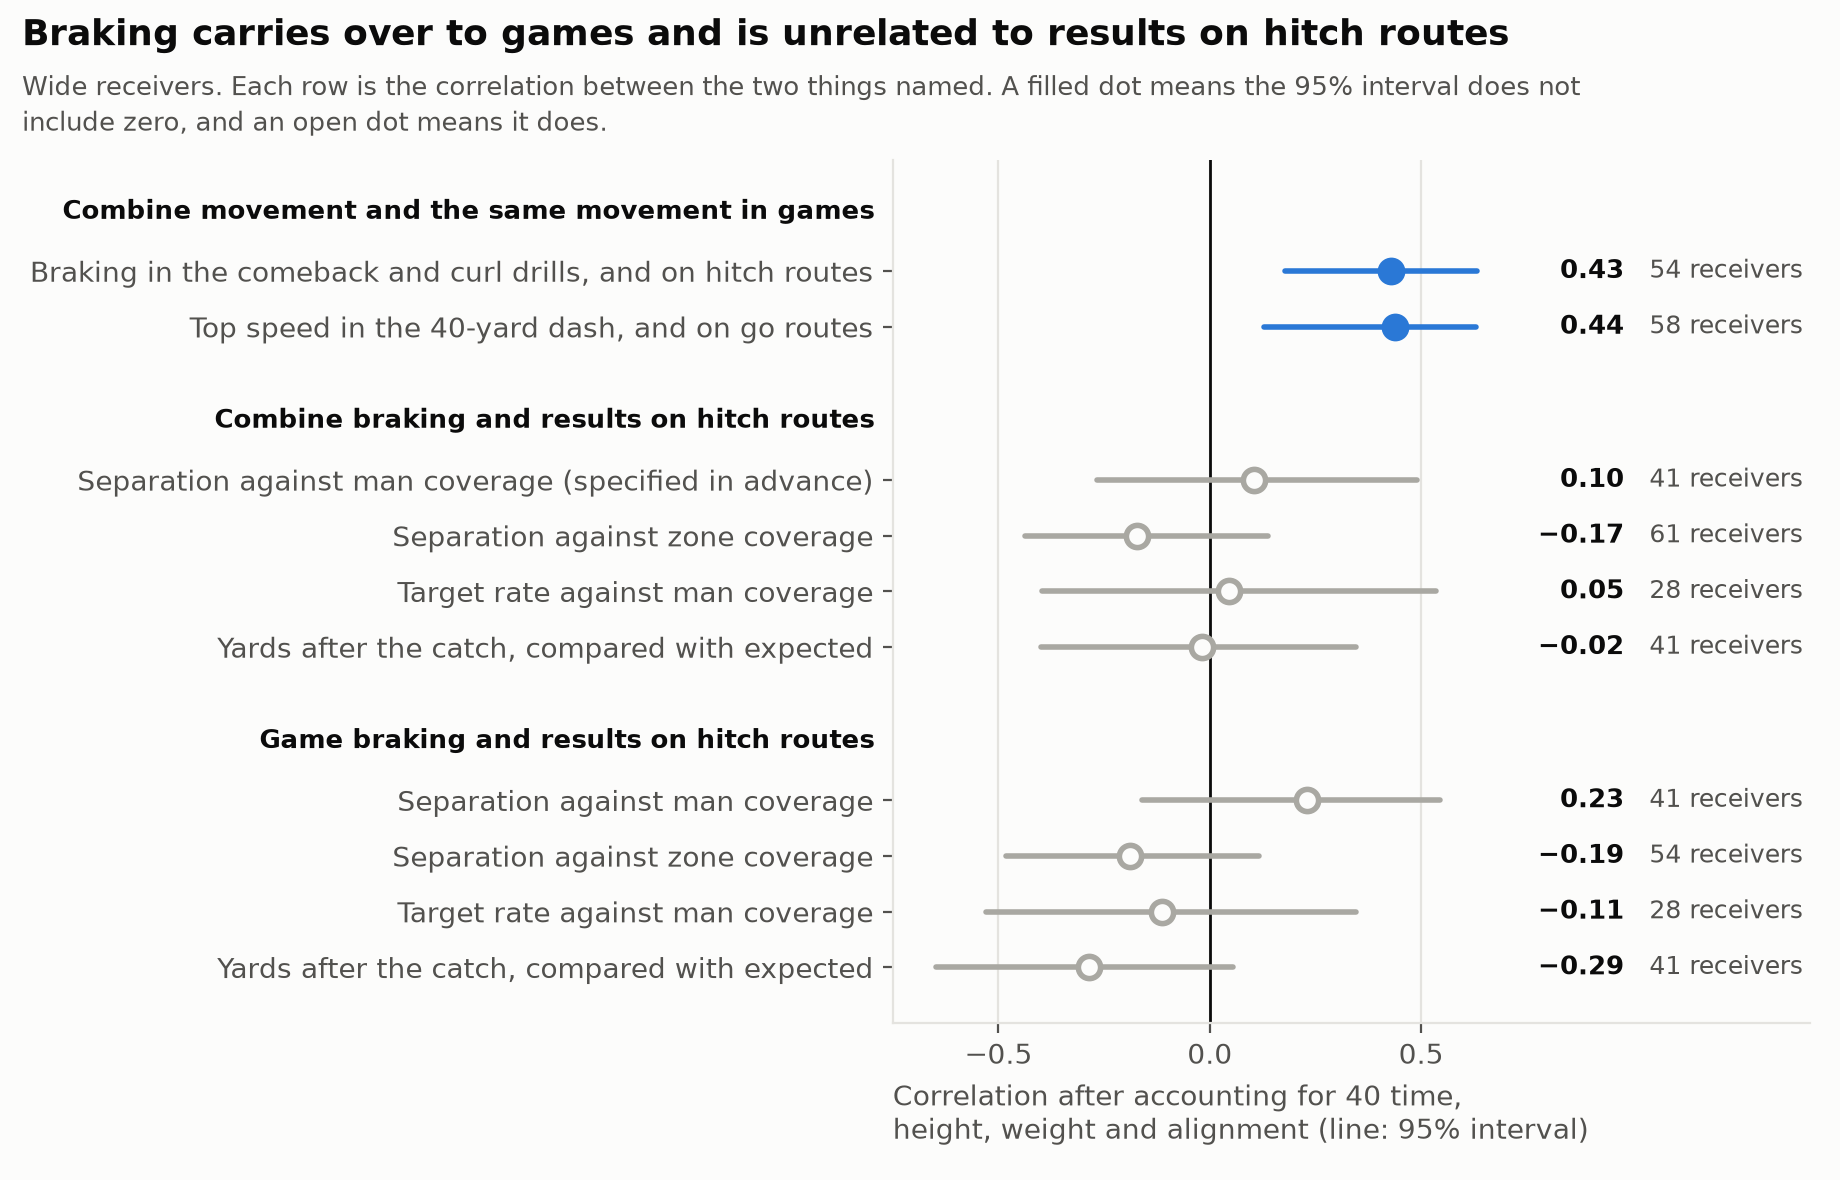

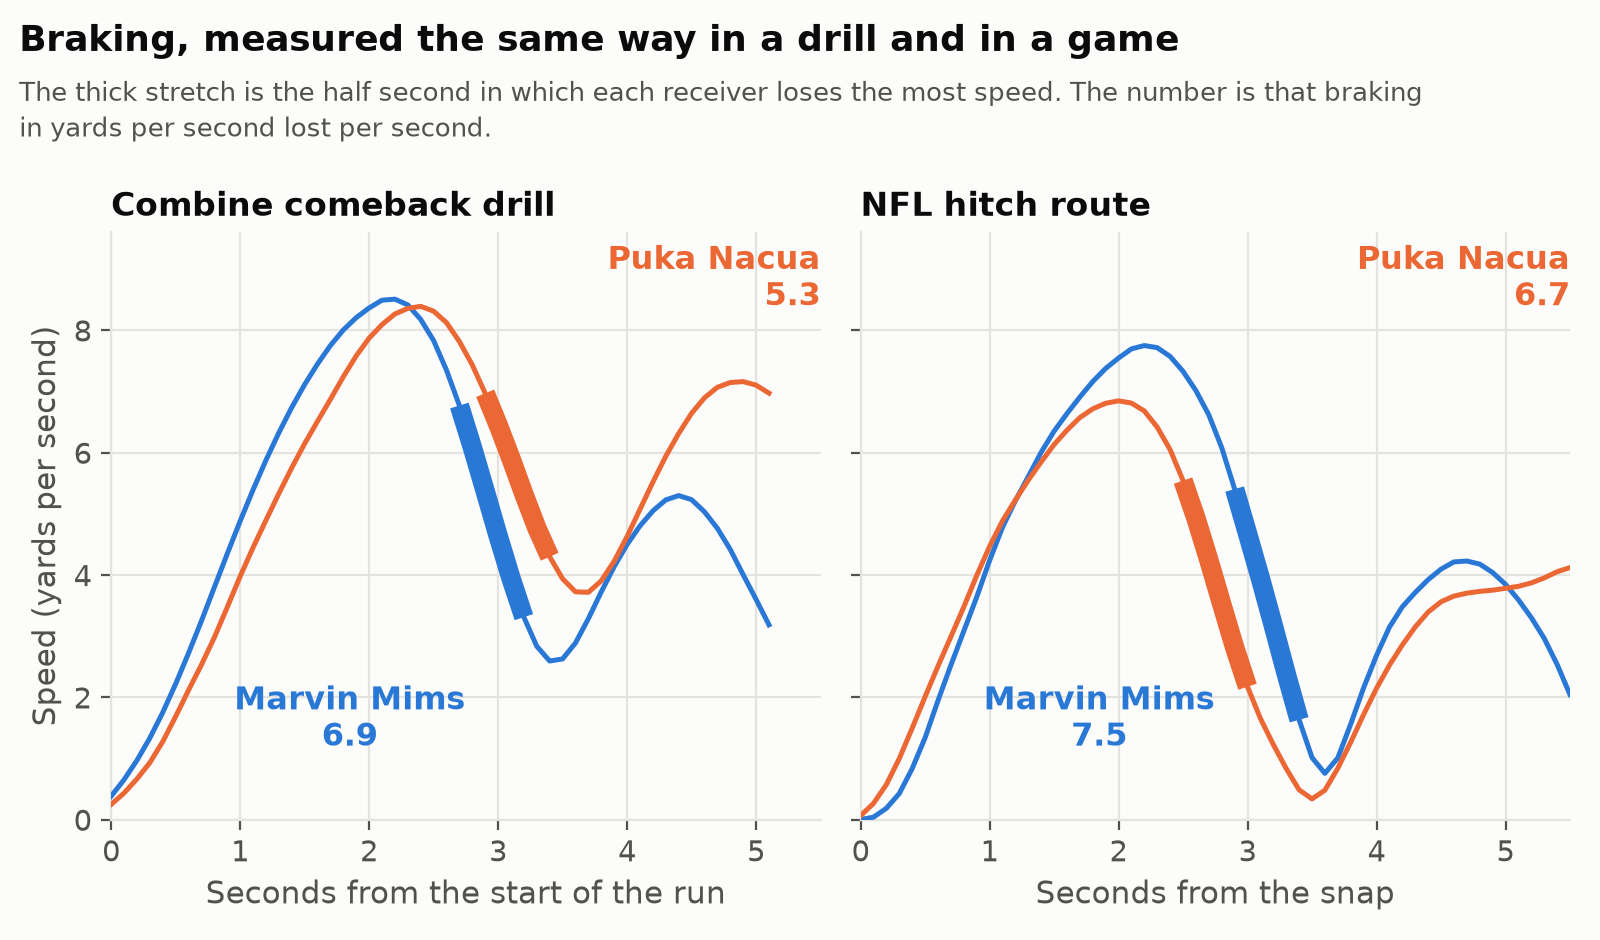

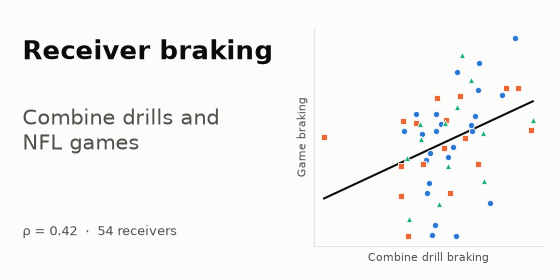

total run time: 8.6 min


In [18]:
paths = figures.save_all(FIG_DIR, stopwatch_frame=report.stopwatch_frame(), scatter=report.scatter(), numbers=numbers,
                         benchmarks=benchmarks, robustness_table=robust, chain_table=chain)
for p in paths:
    display(Image(filename=str(p), width=560 if "card" in p.name else 820))
print(f"total run time: {(time.time() - START) / 60:.1f} min")

## Appendix: neural models (stored results, not re-run here)

Two contrastive networks were trained on Modal earlier in the project. They need PyTorch (`uv sync --extra nn`) and are **not executed by this notebook**; the figures below are the stored summaries from those runs. Neither is used in the writeup's argument.

| Model | Task | Result | Chance |
|---|---|---|---|
| Two-tower "fingerprint" (Combine clips matched to game clips) | pick a player's game clips out of a same-role, same-class line-up | mean normalised rank 0.481, top-1 24.7% (449 players, p = 0.0014) | 0.5, 23.2% |
| Combine-only "signature" (one half of the drills matched to the other half) | re-identify a held-out player from different drills | mean normalised rank 0.391, top-1 31.7% (481 players, p ≈ 6 × 10⁻²¹) | 0.5, 22.9% |

Players have a repeatable movement signature across drills, and a faint trace of it is visible in games, but the embeddings did not predict any outcome. To reproduce: `uv run modal run modal_app.py::main` and `modal_app.py::signature` (see `CLAUDE.md`).